<a href="https://colab.research.google.com/github/DanielLucero25/CSC349/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/DanielLucero25/CSC349/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 349 HW6: Face Images and PCA

This notebook looks at face compression and compares four classification models. Run the cells from top to bottom. Saved outputs were checked in a local Python runtime. Run all cells in Google Colab and save the notebook back to GitHub for the required Colab execution. Training times depend on the computer.

## Task 1: Load and inspect the faces

I load the Olivetti Faces dataset. X holds the pixel values and y holds the ID for each person. Each face is a 64 by 64 image with 4096 pixel values.

I print how many images, people and features are in the data. Then I show 20 faces in a 4 by 5 grid. Each face has its person's ID above it. I pick images from different people so I can see some of the differences.

Samples: 400
Subjects: 40
Features: 4096
Image shape: (64, 64)


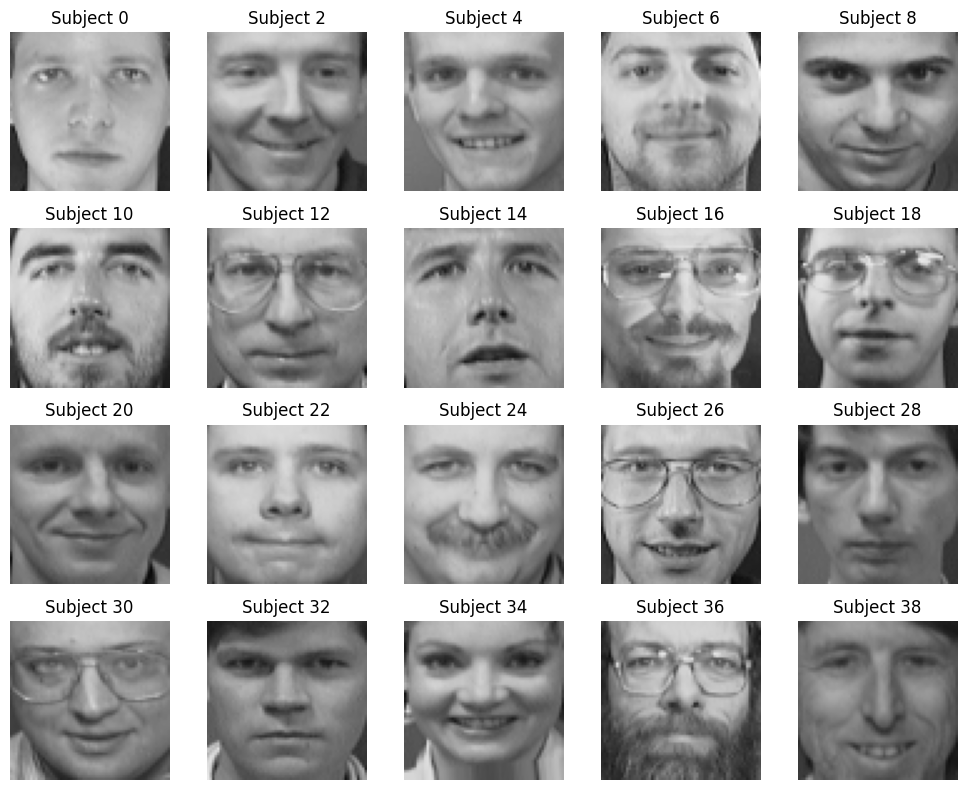

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter

from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, mean_squared_error, ConfusionMatrixDisplay

faces = fetch_olivetti_faces()
X = faces.data
y = faces.target

print('Samples:', X.shape[0])
print('Subjects:', len(np.unique(y)))
print('Features:', X.shape[1])
print('Image shape:', faces.images.shape[1:])

fig, axes = plt.subplots(4, 5, figsize=(10, 8))
for ax, index in zip(axes.ravel(), range(0, 400, 20)):
    ax.imshow(faces.images[index], cmap='gray', vmin=0, vmax=1)
    ax.set_title('Subject ' + str(y[index]))
    ax.axis('off')
plt.tight_layout()
plt.show()

## Task 2: Explained variance

I use PCA to find patterns in the face images. The first graph shows how much of the differences in the images each component explains. The second graph adds these amounts together so I can see how much information is kept as I add more components.

I print how many components are needed to keep 90, 95 and 99 percent of the variance. Variance means how much the pixel values differ across the images. This PCA uses all the images for exploring the data. Later I fit a separate PCA using only the training images for classification.

90% variance: 66 components
95% variance: 123 components
99% variance: 260 components


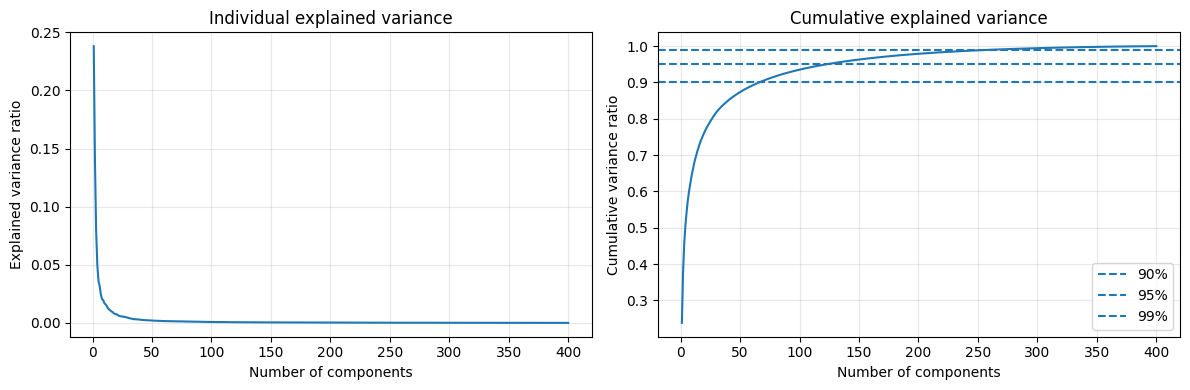

In [ ]:
pca = PCA(svd_solver='full')
pca.fit(X)
variance = pca.explained_variance_ratio_
cumulative = np.cumsum(variance)
components = np.arange(1, len(variance) + 1)

for threshold in [0.90, 0.95, 0.99]:
    count = np.searchsorted(cumulative, threshold) + 1
    print(str(int(threshold * 100)) + '% variance:', count, 'components')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(components, variance)
axes[0].set_title('Individual explained variance')
axes[0].set_ylabel('Explained variance ratio')
axes[1].plot(components, cumulative)
for threshold in [0.90, 0.95, 0.99]:
    axes[1].axhline(threshold, linestyle='--', label=str(int(threshold * 100)) + '%')
axes[1].set_title('Cumulative explained variance')
axes[1].set_ylabel('Cumulative variance ratio')
axes[1].legend()
for ax in axes:
    ax.set_xlabel('Number of components')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 3: Compress and reconstruct faces

I pick five faces from different people. I use PCA to compress them with 10, 50, 100, 200 and 300 components. Then I turn the compressed values back into images. The grid shows each original face next to the versions made with fewer components.

I calculate the mean squared error for each component count. This measures how different the rebuilt pixel values are from the originals. Lower error means a closer match. I show these errors in a table and graph. These five faces were included when fitting PCA so this checks images it has already seen.

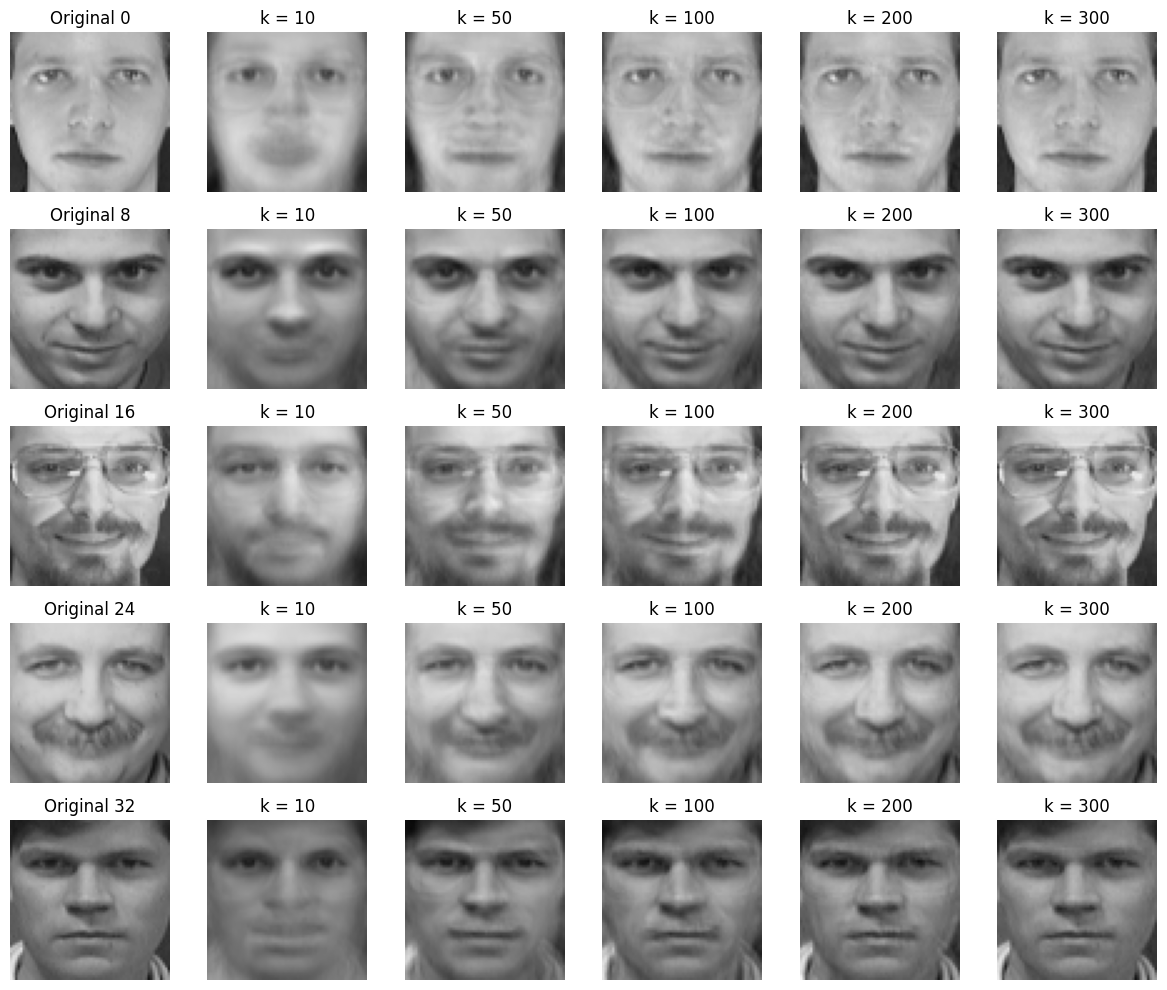

,Components,MSE
0,10,0.005764
1,50,0.002117
2,100,0.001084
3,200,0.000398
4,300,0.000127


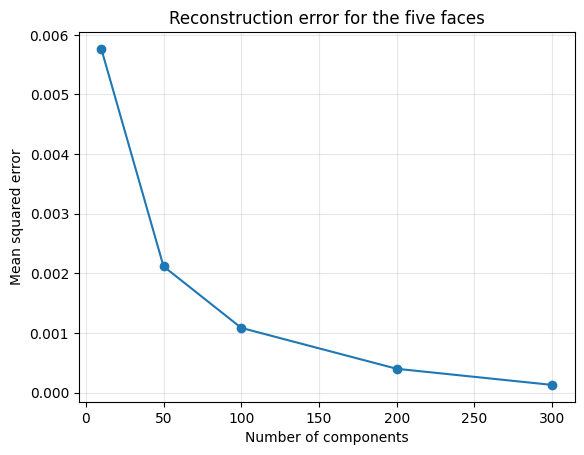

In [ ]:
indices = [0, 80, 160, 240, 320]
selected_faces = X[indices]
k_values = [10, 50, 100, 200, 300]
errors = []

fig, axes = plt.subplots(5, 6, figsize=(12, 10))
for row, index in enumerate(indices):
    axes[row, 0].imshow(faces.images[index], cmap='gray', vmin=0, vmax=1)
    axes[row, 0].set_title('Original ' + str(y[index]))

for column, k in enumerate(k_values, start=1):
    compression = PCA(n_components=k, svd_solver='full')
    compression.fit(X)
    compressed = compression.transform(selected_faces)
    reconstructed = compression.inverse_transform(compressed)
    errors.append(mean_squared_error(selected_faces, reconstructed))
    for row in range(5):
        axes[row, column].imshow(reconstructed[row].reshape(64, 64),
                                cmap='gray', vmin=0, vmax=1)
        axes[row, column].set_title('k = ' + str(k))

for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

reconstruction_results = pd.DataFrame({'Components': k_values, 'MSE': errors})
display(reconstruction_results)
plt.plot(k_values, errors, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Mean squared error')
plt.title('Reconstruction error for the five faces')
plt.grid(alpha=0.3)
plt.show()

## Task 4: Show the eigenfaces

I take the first 15 PCA components and show each one as a 64 by 64 image. These are called eigenfaces. They show patterns of changes in the face images rather than pictures of individual people.

I arrange them in a 3 by 5 grid. Each title shows the component number and the percent of variance it explains. The light and dark areas help show which parts of the face change together.

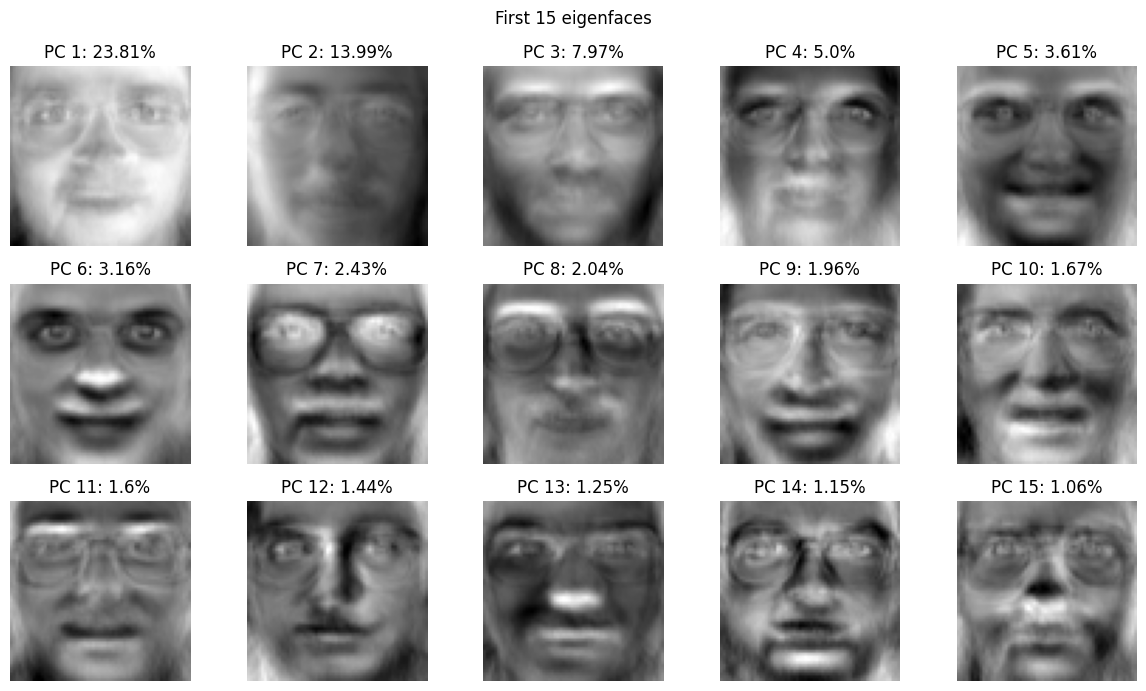

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(pca.components_[i].reshape(64, 64), cmap='gray')
    ax.set_title('PC ' + str(i + 1) + ': ' + str(round(variance[i] * 100, 2)) + '%')
    ax.axis('off')
plt.suptitle('First 15 eigenfaces')
plt.tight_layout()
plt.show()

## Task 5: Logistic regression with raw and PCA features

I split the data into 80 percent for training and 20 percent for testing. I use stratify so both sets have images from every person. I train logistic regression on the original pixel values. Then I train it again using PCA features that keep 95 percent of the training variance.

The PCA pipeline learns only from the training images. It uses the same learned patterns to change the test images. I print the accuracy, training time and number of PCA components. The graph compares accuracy and time with separate axes. Training time includes fitting PCA when it is used but does not include making predictions.

Training images: 320
Test images: 80
Training PCA components: 111
Raw accuracy: 0.9625 Training seconds: 15.7287
PCA accuracy: 0.9625 Training seconds: 0.4592


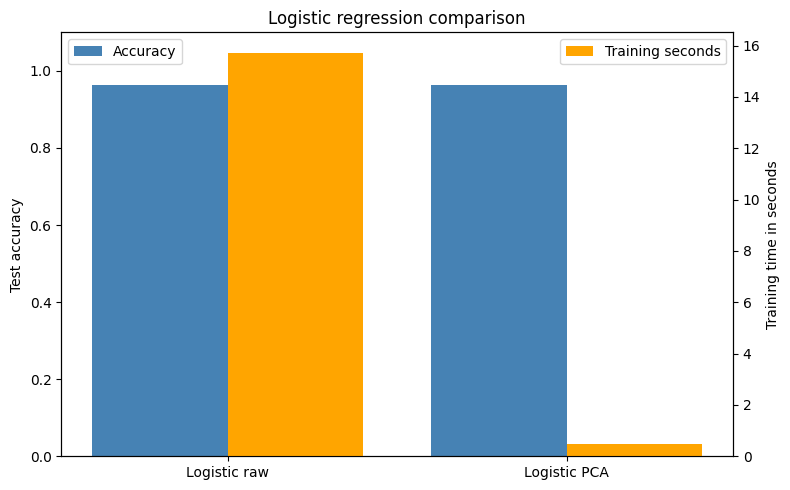

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

raw_model = LogisticRegression(max_iter=2000, random_state=42)
pca_model = Pipeline([
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', LogisticRegression(max_iter=2000, random_state=42))
])

start = perf_counter()
raw_model.fit(X_train, y_train)
raw_time = perf_counter() - start
raw_predictions = raw_model.predict(X_test)
raw_accuracy = accuracy_score(y_test, raw_predictions)

start = perf_counter()
pca_model.fit(X_train, y_train)
pca_time = perf_counter() - start
pca_predictions = pca_model.predict(X_test)
pca_accuracy = accuracy_score(y_test, pca_predictions)

print('Training images:', X_train.shape[0])
print('Test images:', X_test.shape[0])
print('Training PCA components:', pca_model.named_steps['pca'].n_components_)
print('Raw accuracy:', raw_accuracy, 'Training seconds:', round(raw_time, 4))
print('PCA accuracy:', pca_accuracy, 'Training seconds:', round(pca_time, 4))

positions = np.arange(2)
fig, ax1 = plt.subplots(figsize=(8, 5))
ax2 = ax1.twinx()
ax1.bar(positions - 0.2, [raw_accuracy, pca_accuracy], width=0.4,
        color='steelblue', label='Accuracy')
ax2.bar(positions + 0.2, [raw_time, pca_time], width=0.4,
        color='orange', label='Training seconds')
ax1.set_xticks(positions, ['Logistic raw', 'Logistic PCA'])
ax1.set_ylim(0, 1.1)
ax1.set_ylabel('Test accuracy')
ax2.set_ylabel('Training time in seconds')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.title('Logistic regression comparison')
plt.tight_layout()
plt.show()

## Task 6: RBF kernel SVM

I train an SVC with an RBF kernel using the same training and test images. This model can use curved boundaries to separate the different people. PCA first reduces the features while keeping 95 percent of the training variance.

I print how long training takes and how many test images the model gets right. I also show its confusion matrix next to the one for logistic regression with PCA. The diagonal shows correct predictions. The other squares show which people the models mixed up.

In [ ]:
svm_model = Pipeline([
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', SVC(kernel='rbf', random_state=42))
])
start = perf_counter()
svm_model.fit(X_train, y_train)
svm_time = perf_counter() - start
svm_predictions = svm_model.predict(X_test)
svm_accuracy = accuracy_score(y_test, svm_predictions)
print('RBF SVC accuracy:', svm_accuracy)
print('Training seconds:', round(svm_time, 4))

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
ConfusionMatrixDisplay.from_predictions(y_test, pca_predictions, ax=axes[0],
                                       colorbar=False, cmap='Blues')
ConfusionMatrixDisplay.from_predictions(y_test, svm_predictions, ax=axes[1],
                                       colorbar=False, cmap='Blues')
axes[0].set_title('Logistic regression PCA')
axes[1].set_title('RBF SVC PCA')
plt.tight_layout()
plt.show()

RBF SVC accuracy: 0.9375
Training seconds: 0.1798


## Task 7: Soft voting ensemble

I combine three models. They are a degree 2 polynomial SVM, an RBF SVM and a random forest with 100 trees. They all use PCA features learned from the training images.

I use soft voting to average the probabilities from the three models and choose a person. Both SVMs use probability=True so they can give these probabilities. I print the accuracy and total training time. Then I compare the accuracy with logistic regression and the RBF SVC using PCA. Combining models may help but it does not always give a better score.

In [ ]:
voting = VotingClassifier(estimators=[
    ('poly', SVC(kernel='poly', degree=2, probability=True, random_state=42)),
    ('rbf', SVC(kernel='rbf', probability=True, random_state=42)),
    ('forest', RandomForestClassifier(n_estimators=100, random_state=42))
], voting='soft')

ensemble_model = Pipeline([
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', voting)
])
start = perf_counter()
ensemble_model.fit(X_train, y_train)
ensemble_time = perf_counter() - start
ensemble_predictions = ensemble_model.predict(X_test)
ensemble_accuracy = accuracy_score(y_test, ensemble_predictions)
print('Soft voting accuracy:', ensemble_accuracy)
print('Training seconds:', round(ensemble_time, 4))

plt.bar(['Logistic PCA', 'RBF SVC PCA', 'Soft voting PCA'],
        [pca_accuracy, svm_accuracy, ensemble_accuracy])
plt.ylabel('Test accuracy')
plt.ylim(0, 1.1)
plt.title('Models using PCA features')
plt.tight_layout()
plt.show()

## Task 8: Compare all four models

I put all four models in one table and graph. I compare their test accuracy and training time. All models use the same 80 test images so they are checked on the same examples.

The blue bars show accuracy and the orange bars show time in seconds. They use separate axes because the units are different. Training time includes fitting PCA for the models that use it. Times can change on another run. These results show how the models did on this small dataset and may be different with other images.

In [ ]:
results = pd.DataFrame({
    'Model': ['Logistic raw', 'Logistic PCA', 'RBF SVC PCA', 'Soft voting PCA'],
    'Accuracy': [raw_accuracy, pca_accuracy, svm_accuracy, ensemble_accuracy],
    'Training seconds': [raw_time, pca_time, svm_time, ensemble_time]
})
display(results)

positions = np.arange(4)
fig, ax1 = plt.subplots(figsize=(11, 6))
ax2 = ax1.twinx()
accuracy_bars = ax1.bar(positions - 0.2, results['Accuracy'], width=0.4,
                        color='steelblue', label='Accuracy')
time_bars = ax2.bar(positions + 0.2, results['Training seconds'], width=0.4,
                   color='orange', label='Training seconds')
ax1.bar_label(accuracy_bars, fmt='%.3f', padding=3)
ax2.bar_label(time_bars, fmt='%.3f', padding=3)
ax1.set_xticks(positions, results['Model'])
ax1.set_ylim(0, 1.2)
ax2.set_ylim(0, results['Training seconds'].max() * 1.25)
ax1.set_ylabel('Test accuracy')
ax2.set_ylabel('Training time in seconds')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.title('Accuracy and training time for all models')
plt.tight_layout()
plt.show()